Found 7790 images in ..\data


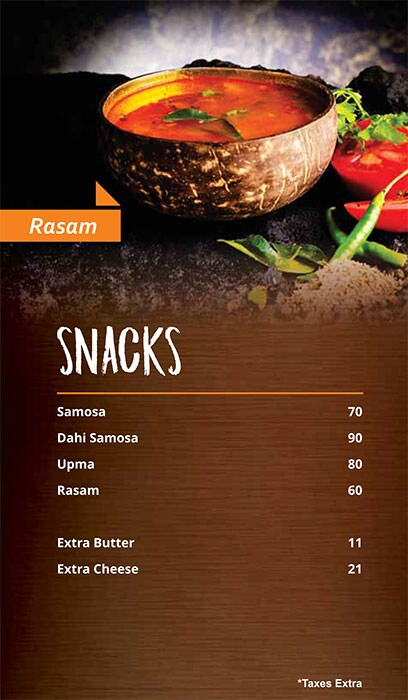

1.jpg


In [11]:
from pathlib import Path
from PIL import Image
import zipfile, os

IMAGE_DIR = Path('../data')
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
image_paths = sorted(p for p in IMAGE_DIR.rglob('*') if p.suffix.lower() in IMAGE_EXTS)
print(f'Found {len(image_paths)} images in {IMAGE_DIR}')
if image_paths:
    display(Image.open(image_paths[0]).convert('RGB'))
    print(image_paths[0].name)

In [4]:
import pandas as pd
from PIL import Image

inventory = []
for p in image_paths:
    try:
        with Image.open(p) as im:
            inventory.append({'filename': p.name, 'path': str(p), 'width': im.width,
                              'height': im.height, 'format': im.format,
                              'file_kb': round(p.stat().st_size / 1024, 1)})
    except Exception as e:
        inventory.append({'filename': p.name, 'path': str(p), 'error': str(e)})

inventory_df = pd.DataFrame(inventory)
display(inventory_df.head(20))
print('Total images:', len(inventory_df))

,filename,path,width,height,format,file_kb,error
0,1.jpg,..\data\1.jpg,408.0,700.0,JPEG,61.4,NaN
1,10.jpg,..\data\10.jpg,350.0,580.0,JPEG,33.4,NaN
2,100.jpg,..\data\100.jpg,650.0,652.0,JPEG,108.3,NaN
3,1000.jpg,..\data\1000.jpg,389.0,550.0,JPEG,43.3,NaN
4,1001.jpg,..\data\1001.jpg,422.0,700.0,JPEG,59.2,NaN
5,1002.jpg,..\data\1002.jpg,379.0,550.0,JPEG,55.7,NaN
6,1003.jpg,..\data\1003.jpg,384.0,700.0,JPEG,70.0,NaN
7,1004.jpg,..\data\1004.jpg,404.0,616.0,JPEG,29.7,NaN
8,1005.jpg,..\data\1005.jpg,474.0,600.0,JPEG,58.4,NaN
9,1006.jpg,..\data\1006.jpg,486.0,700.0,JPEG,131.1,NaN


Total images: 7790


In [5]:
from paddleocr import PaddleOCR

# Use one OCR instance first. If your images are mainly in Devanagari, try lang='devanagari'.
ocr = PaddleOCR(lang='en')
print('PaddleOCR ready')

c:\ProjectFiles\hacktoberfest\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\ProjectFiles\hacktoberfest\.venv\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-LCNet_x1_0_doc_ori', None, None)
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.
Using official model (PP-LCNet_x1_0_doc_ori), the model files will be automatically downloaded and saved in `C:\Users\a_sri\.paddlex\official_models\PP-LCNet_x1_0_doc_ori`.
Fetching 6 files: 100%|██████████

PaddleOCR ready


In [7]:
import sys
import paddle
import paddleocr
import paddlex

print("Python:", sys.version)
print("PaddlePaddle:", paddle.__version__)
print("PaddleOCR:", paddleocr.__version__)
print("PaddleX:", paddlex.__version__)
print("Paddle device:", paddle.device.get_device())

Python: 3.11.0 (main, Oct 24 2022, 18:26:48) [MSC v.1933 64 bit (AMD64)]
PaddlePaddle: 3.3.1
PaddleOCR: 3.7.0
PaddleX: 3.7.2
Paddle device: cpu


In [10]:
def run_paddle_ocr(image_path):
    results = ocr.predict(str(image_path))
    rows = []
    for result in results:
        texts = result.get('rec_texts', [])
        scores = result.get('rec_scores', [])
        boxes = result.get('rec_boxes', [])
        for i, text in enumerate(texts):
            score = float(scores[i]) if i < len(scores) else None
            box = boxes[i].tolist() if i < len(boxes) and hasattr(boxes[i], 'tolist') else (boxes[i] if i < len(boxes) else None)
            rows.append({'text': str(text), 'confidence': score, 'box': box})
    return rows

# Smoke test on the first imagedef run_paddle_ocr(image_path):
    results = ocr.predict(str(image_path))
    rows = []

    for result in results:
        if hasattr(result, "json"):
            data = result.json
            if callable(data):
                data = data()
            if isinstance(data, dict) and "res" in data:
                data = data["res"]
        elif isinstance(result, dict):
            data = result
        else:
            continue

        texts = data.get("rec_texts", [])
        scores = data.get("rec_scores", [])
        boxes = data.get("rec_boxes", [])

        for i, text in enumerate(texts):
            score = float(scores[i]) if i < len(scores) else None

            box = None
            if i < len(boxes):
                box = boxes[i]
                if hasattr(box, "tolist"):
                    box = box.tolist()

            rows.append({
                "text": str(text),
                "confidence": score,
                "box": box
            })

    return rows


if image_paths:
    # Disable oneDNN/MKLDNN to avoid the unsupported PIR attribute conversion.
    ocr = PaddleOCR(lang="en", enable_mkldnn=False)
    test_rows = run_paddle_ocr(image_paths[0])
    display(pd.DataFrame(test_rows))
else:
    print("No images found. Upload a ZIP or set IMAGE_DIR first.")
if image_paths:
    test_rows = run_paddle_ocr(image_paths[0])
    display(pd.DataFrame(test_rows))
else:
    print('No images found. Upload a ZIP or set IMAGE_DIR first.')

Creating model: ('PP-LCNet_x1_0_doc_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\a_sri\.paddlex\official_models\PP-LCNet_x1_0_doc_ori`.


Creating model: ('UVDoc', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\a_sri\.paddlex\official_models\UVDoc`.
Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\a_sri\.paddlex\official_models\PP-LCNet_x1_0_textline_ori`.
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\a_sri\.paddlex\official_models\PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\a_sri\.paddlex\official_models\PP-OCRv6_medium_rec`.


,text,confidence,box
0,Rasam,0.999995,"[21, 168, 111, 200]"
1,SNACKS,0.999948,"[44, 291, 206, 372]"
2,Samosa,0.999988,"[51, 395, 113, 412]"
3,70,0.999997,"[380, 397, 403, 416]"
4,Dahi Samosa,0.999583,"[52, 424, 148, 440]"
5,90,0.999990,"[378, 427, 400, 443]"
6,Upma,0.999977,"[51, 453, 98, 472]"
7,80,0.999997,"[376, 455, 397, 472]"
8,Rasam,0.999991,"[50, 483, 104, 500]"
9,60,0.999997,"[374, 483, 395, 501]"


,text,confidence,box
0,Rasam,0.999995,"[21, 168, 111, 200]"
1,SNACKS,0.999948,"[44, 291, 206, 372]"
2,Samosa,0.999988,"[51, 395, 113, 412]"
3,70,0.999997,"[380, 397, 403, 416]"
4,Dahi Samosa,0.999583,"[52, 424, 148, 440]"
5,90,0.999990,"[378, 427, 400, 443]"
6,Upma,0.999977,"[51, 453, 98, 472]"
7,80,0.999997,"[376, 455, 397, 472]"
8,Rasam,0.999991,"[50, 483, 104, 500]"
9,60,0.999997,"[374, 483, 395, 501]"


In [12]:
import re
import pandas as pd

def pair_dishes_with_prices(rows):
    items = []

    for row in rows:
        box = row["box"]
        if box is None:
            continue

        x1, y1, x2, y2 = box
        items.append({
            "text": row["text"].strip(),
            "confidence": row["confidence"],
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2,
            "cy": (y1 + y2) / 2
        })

    prices = [
        item for item in items
        if re.fullmatch(r"(?:₹\s*)?\d+(?:\.\d{1,2})?", item["text"])
    ]

    dishes = [
        item for item in items
        if item not in prices
        and re.search(r"[A-Za-z\u0900-\u097F]", item["text"])
    ]

    pairs = []
    used_dishes = set()

    for price in prices:
        candidates = [
            dish for dish in dishes
            if dish["x1"] < price["x1"]
            and dish["cy"] not in used_dishes
        ]

        if not candidates:
            continue

        dish = min(candidates, key=lambda d: abs(d["cy"] - price["cy"]))

        pairs.append({
            "dish": dish["text"],
            "price": price["text"],
            "dish_confidence": dish["confidence"],
            "price_confidence": price["confidence"],
            "vertical_gap": round(abs(dish["cy"] - price["cy"]), 1)
        })

        used_dishes.add(dish["cy"])

    return pd.DataFrame(pairs)

display(pair_dishes_with_prices(test_rows))

,dish,price,dish_confidence,price_confidence,vertical_gap
0,Samosa,70,0.999988,0.999997,3.0
1,Dahi Samosa,90,0.999583,0.999990,3.0
2,Upma,80,0.999977,0.999997,1.0
3,Rasam,60,0.999991,0.999997,0.5
4,Extra Butter,11,0.999983,0.999972,1.0
5,Extra Cheese,21,0.999985,0.999998,1.0


In [14]:
import time
import pandas as pd

print("Total images:", len(image_paths))

start = time.time()
all_results = []

for image_path in image_paths[:3]:
    rows = run_paddle_ocr(image_path)
    paired = pair_dishes_with_prices(rows)

    for _, item in paired.iterrows():
        all_results.append({
            "image": str(image_path),
            **item.to_dict()
        })

    print(
        f"Processed {image_path.name} | "
        f"Elapsed: {(time.time() - start):.1f}s"
    )

results_df = pd.DataFrame(all_results)
display(results_df)

Total images: 7790
Processed 1.jpg | Elapsed: 10.8s
Processed 10.jpg | Elapsed: 38.1s
Processed 100.jpg | Elapsed: 76.8s


,image,dish,price,dish_confidence,price_confidence,vertical_gap
0,..\data\1.jpg,Samosa,70,0.999988,0.999997,3.0
1,..\data\1.jpg,Dahi Samosa,90,0.999583,0.999990,3.0
2,..\data\1.jpg,Upma,80,0.999977,0.999997,1.0
3,..\data\1.jpg,Rasam,60,0.999991,0.999997,0.5
4,..\data\1.jpg,Extra Butter,11,0.999983,0.999972,1.0
5,..\data\1.jpg,Extra Cheese,21,0.999985,0.999998,1.0
6,..\data\100.jpg,turmeric,250,0.958243,0.999364,41.0
